# Worksheet: Image Spatial Transformation

ใบงานนี้เรียนรู้การแปลงตำแหน่งพิกเซลด้วยเมทริกซ์ ได้แก่ **translation, scaling, rotation** และ **matrix composition** เนื้อหาและลำดับโค้ดอ้างอิงจาก worksheet ต้นฉบับ แต่ปรับให้ฟังก์ชันเดียวรองรับทั้งภาพระดับเทาและภาพสี

เมื่อจบใบงาน นักศึกษาจะสามารถ

- แทนพิกัดภาพด้วย `[x, y, 1]`
- สร้างเมทริกซ์ translation, scaling และ rotation
- หาตำแหน่งใหม่ด้วย `np.matmul(xy, M)`
- ประกอบหลาย transformation ไว้ในเมทริกซ์ `T`
- ใช้ `img_transform(img, T)` กับภาพระดับเทาและภาพสี
- ใช้ median filtering ลดช่องว่างจาก forward mapping ชั่วคราว

ใบงานนี้ยังไม่ลงรายละเอียดเรื่อง interpolation

In [53]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1) ระบบพิกัดและเมทริกซ์

- ภาพระดับเทามี shape `(H, W)`
- ภาพสีมี shape `(H, W, 3)`
- พิกัดเขียนเป็น `(x, y)` แต่เวลาเข้าถึงอาร์เรย์ใช้ `img[y, x]`
- จุด `(0, 0)` อยู่มุมซ้ายบน แกน `x` ชี้ไปทางขวา และแกน `y` ชี้ลง

เราเขียนพิกัดเป็น row vector โดยเติม `1` ไว้ท้ายพิกัด

$$
xy=\begin{bmatrix}x&y&1\end{bmatrix}
$$

ตำแหน่งใหม่หาได้จาก

$$
new\_xy=xyM
$$

ใน Python ใช้คำสั่ง

```python
new_xy = np.matmul(xy, M)
```

In [54]:
def show_image(image, title=""):
    plt.figure(figsize=(4, 4))
    if image.ndim == 2:
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()


def show_images(images, titles):
    plt.figure(figsize=(4 * len(images), 4))
    for index, (image, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(1, len(images), index)
        if image.ndim == 2:
            plt.imshow(image, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(image)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## 2) อ่านภาพตัวอย่าง

OpenCV อ่านภาพสีเป็น BGR แต่ Matplotlib ใช้ RGB จึงต้องแปลงลำดับช่องสีก่อนแสดงผล

ภาพระดับเทา: (512, 512) uint8
ภาพสี RGB  : (256, 256, 3) uint8


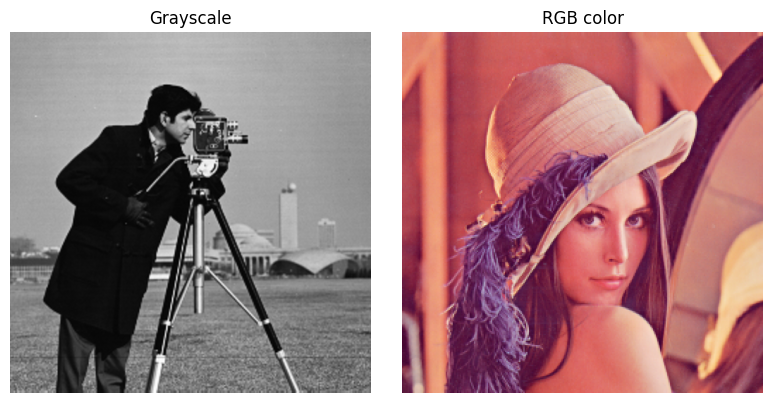

In [55]:
gray_image = cv2.imread("../images/cameraman.png", cv2.IMREAD_GRAYSCALE)
color_bgr = cv2.imread("../images/lena_color_256.png", cv2.IMREAD_COLOR)

if gray_image is None or color_bgr is None:
    raise FileNotFoundError("ไม่พบภาพตัวอย่างในโฟลเดอร์ ./images")

color_image = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2RGB)

print("ภาพระดับเทา:", gray_image.shape, gray_image.dtype)
print("ภาพสี RGB  :", color_image.shape, color_image.dtype)
show_images([gray_image, color_image], ["Grayscale", "RGB color"])

## 3) Translation: การเลื่อนภาพ

Translation matrix สำหรับ row vector คือ

$$
Ts=
\begin{bmatrix}
1&0&0\\
0&1&0\\
t_x&t_y&1
\end{bmatrix}
$$

- `tx > 0` เลื่อนไปทางขวา และ `tx < 0` เลื่อนไปทางซ้าย
- `ty > 0` เลื่อนลง และ `ty < 0` เลื่อนขึ้น
- พิกเซลที่ออกนอกกรอบจะถูกตัด ส่วนพื้นที่ใหม่จะแสดงเป็นสีดำ

In [56]:
def img_translation(img, tx, ty):
    out = np.zeros_like(img, dtype="uint8")

    Ts = np.identity(3, dtype='float') # create Mathix เอกลักษณ์ คือ 1แนวทะแยง
    Ts[2, 0] = tx       # [1  0  0]
    Ts[2, 1] = ty  #->  # [0  1  0]
                        # [tx ty 1]
    rows, cols = img.shape[:2]

    for y in range(rows):
        for x in range(cols):
            xy = np.array([x, y, 1], dtype=float) # create mathix [x,y,1]
            new_xy = np.matmul(xy, Ts) 

            new_x = int(new_xy[0])
            new_y = int(new_xy[1])

            if 0 <= new_x < cols and 0 <= new_y < rows:
                out[new_y, new_x] = img[y, x]

    return out.astype(np.uint8)

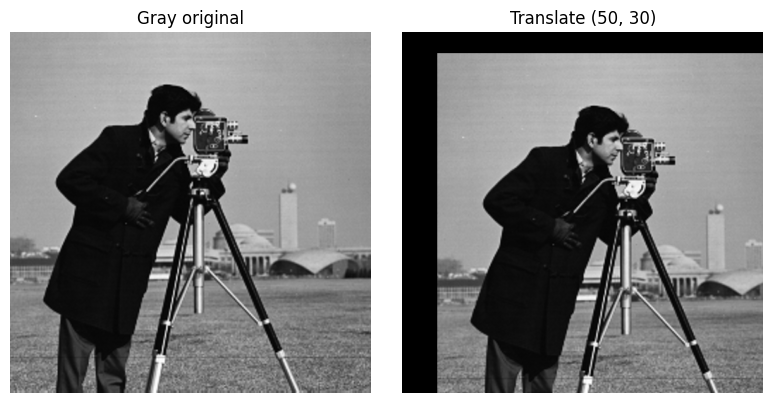

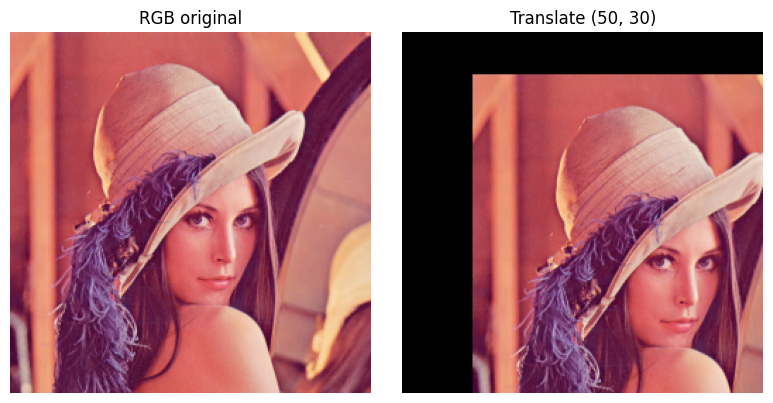

In [57]:
gray_moved = img_translation(gray_image, tx=50, ty=30)
color_moved = img_translation(color_image, tx=50, ty=30)

show_images([gray_image, gray_moved], ["Gray original", "Translate (50, 30)"])
show_images([color_image, color_moved], ["RGB original", "Translate (50, 30)"])

## 4) Scaling: การย่อและขยาย

Scaling matrix คือ

$$
S=
\begin{bmatrix}
s_x&0&0\\
0&s_y&0\\
0&0&1
\end{bmatrix}
$$

- ค่า `sx` หรือ `sy` ระหว่าง `0` ถึง `1` ทำให้ภาพเล็กลง
- ค่ามากกว่า `1` ทำให้ภาพใหญ่ขึ้น และส่วนที่เกินกรอบจะถูกตัด
- ถ้า `sx` กับ `sy` ไม่เท่ากัน สัดส่วนภาพจะเปลี่ยน

ฟังก์ชันนี้ scaling รอบจุด `(0, 0)` จึงเห็นภาพผลลัพธ์ชิดมุมซ้ายบน

In [58]:
def img_scaling(img, sx, sy):
    out = np.zeros_like(img, dtype="uint8")

    S = np.identity(3, dtype=float)
    S[0, 0] = sx
    S[1, 1] = sy

    rows, cols = img.shape[:2]

    for y in range(rows):
        for x in range(cols):
            xy = np.array([x, y, 1], dtype=float)
            new_xy = np.matmul(xy, S)

            new_x = int(new_xy[0])
            new_y = int(new_xy[1])

            if 0 <= new_x < cols and 0 <= new_y < rows:
                out[new_y, new_x] = img[y, x]

    return out.astype(np.uint8)

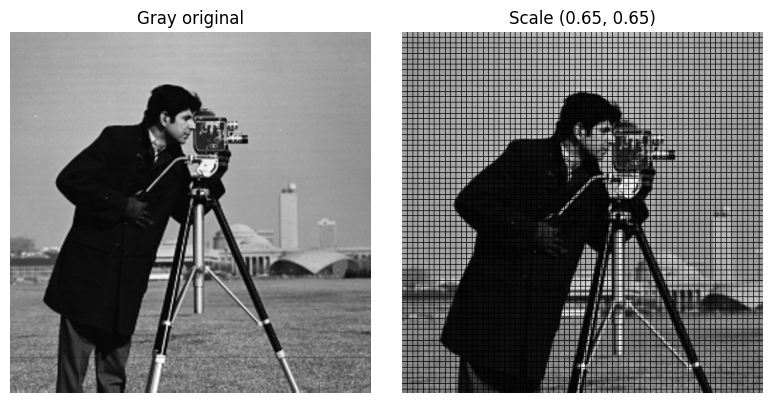

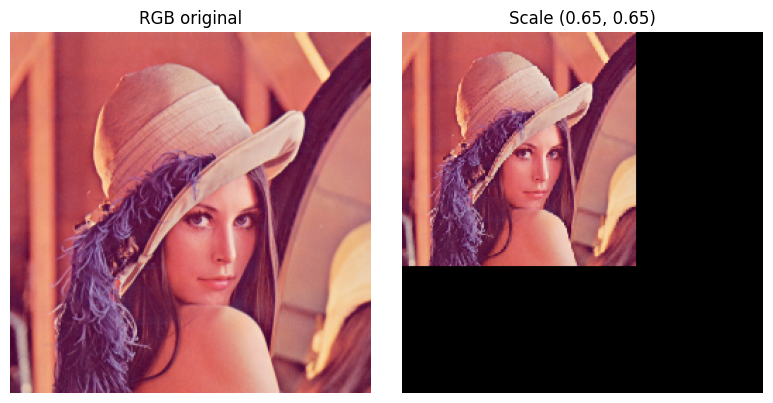

In [59]:
gray_scaled = img_scaling(gray_image, sx=1.15, sy=1.15)
color_scaled = img_scaling(color_image, sx=0.65, sy=0.65)

show_images([gray_image, gray_scaled], ["Gray original", "Scale (0.65, 0.65)"])
show_images([color_image, color_scaled], ["RGB original", "Scale (0.65, 0.65)"])

## 5) Rotation: การหมุนภาพ

Rotation matrix สำหรับ row vector คือ

$$
R=
\begin{bmatrix}
\cos\theta&-\sin\theta&0\\
\sin\theta&\cos\theta&0\\
0&0&1
\end{bmatrix}
$$

ค่ามุมในโค้ดใช้หน่วยองศา จึงแปลงเป็นเรเดียนก่อนใช้ `sin` และ `cos` ฟังก์ชันนี้หมุนรอบจุด `(0, 0)` ภาพบางส่วนจึงอาจออกนอกกรอบ

In [60]:
def img_rotation(img, theta):
    out = np.zeros_like(img, dtype="uint8")

    R = np.identity(3, dtype=float)
    angle = (theta * np.pi) / 180
    R[0, 0] = np.cos(angle)
    R[0, 1] = -np.sin(angle)
    R[1, 0] = np.sin(angle)
    R[1, 1] = np.cos(angle)

    rows, cols = img.shape[:2]

    for y in range(rows):
        for x in range(cols):
            xy = np.array([x, y, 1], dtype=float)
            new_xy = np.matmul(xy, R)

            new_x = int(new_xy[0])
            new_y = int(new_xy[1])

            if 0 <= new_x < cols and 0 <= new_y < rows:
                out[new_y, new_x] = img[y, x]

    return out.astype(np.uint8)

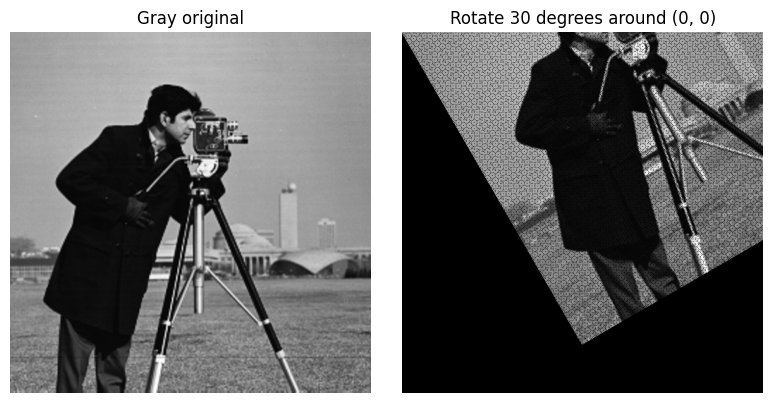

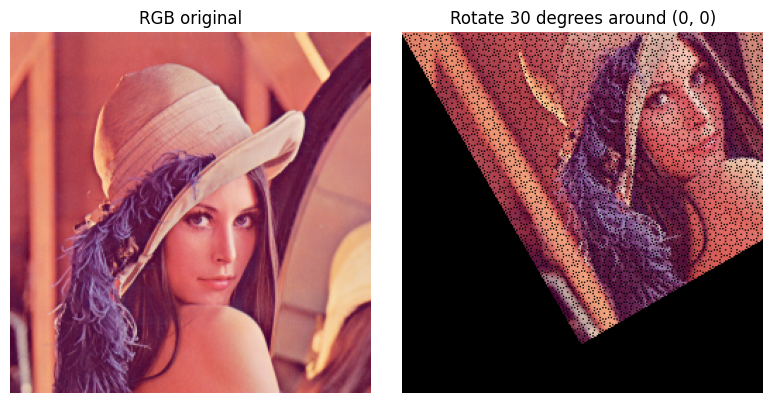

In [61]:
gray_rotated_origin = img_rotation(gray_image, theta=30)
color_rotated_origin = img_rotation(color_image, theta=30)

show_images(
    [gray_image, gray_rotated_origin],
    ["Gray original", "Rotate 30 degrees around (0, 0)"],
)
show_images(
    [color_image, color_rotated_origin],
    ["RGB original", "Rotate 30 degrees around (0, 0)"],
)

## 6) Transformation Matrix สำหรับหลายการแปลง

ถ้าต้องการให้ภาพหมุนหรือ scaling รอบจุดกึ่งกลาง ต้องใช้ translation ร่วมด้วย แทนที่จะเขียนลูปใหม่ เราจะสร้างเมทริกซ์ `T` แล้วใช้ฟังก์ชัน `img_transform(img, T)`

ทุกฟังก์ชันด้านล่างรับ `T` เดิม สร้างเมทริกซ์ของ transformation ใหม่ แล้วใช้ `np.matmul(new_matrix, T)` ตามโครงสร้างต้นฉบับ

In [62]:
def init_Transformation():
    return np.identity(3, dtype=float)

In [63]:
def matrix_Translate(T, tx, ty):
    Ts = np.identity(3, dtype=float)
    Ts[2, 0] = tx
    Ts[2, 1] = ty
    return np.matmul(Ts, T)

In [64]:
def matrix_Scale(T, sx, sy):
    S = np.identity(3, dtype=float)
    S[0, 0] = sx
    S[1, 1] = sy
    return np.matmul(S, T)

In [65]:
def matrix_Rotatef(T, theta):
    R = np.identity(3, dtype=float)
    angle = (theta * np.pi) / 180
    R[0, 0] = np.cos(angle)
    R[0, 1] = -np.sin(angle)
    R[1, 0] = np.sin(angle)
    R[1, 1] = np.cos(angle)
    return np.matmul(R, T)

In [66]:
def centroid_image(img):
    rows, cols = img.shape[:2]
    return int(rows / 2), int(cols / 2)

In [67]:
def img_transform(img, T):
    out = np.zeros_like(img, dtype="uint8")+255
    rows, cols = img.shape[:2]

    for y in range(rows):
        for x in range(cols):
            xy = np.array([x, y, 1], dtype=float)
            new_xy = np.matmul(xy, T)

            new_x = int(new_xy[0])
            new_y = int(new_xy[1])

            if 0 <= new_x < cols and 0 <= new_y < rows:
                out[new_y, new_x] = img[y, x]

    return out.astype(np.uint8)

## 7) Scaling รอบจุดกึ่งกลาง

เริ่มจาก identity matrix แล้วประกอบ translation และ scaling ตามลำดับเดิม

```python
T = init_Transformation()
T = matrix_Translate(T, cen[1], cen[0])
T = matrix_Scale(T, 0.6, 0.6)
T = matrix_Translate(T, -cen[1], -cen[0])
out = img_transform(img, T)
```

`cen[0]` คือพิกัดแถวหรือ `y` และ `cen[1]` คือพิกัดคอลัมน์หรือ `x`

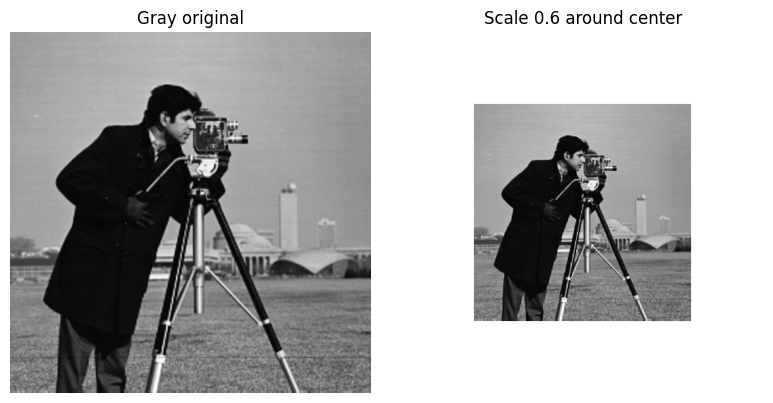

In [68]:
img = gray_image
cen = centroid_image(img)

T = init_Transformation()
T = matrix_Translate(T, cen[1], cen[0])
T = matrix_Scale(T, 0.6, 0.6)
T = matrix_Translate(T, -cen[1], -cen[0])

out = img_transform(img, T)
show_images([img, out], ["Gray original", "Scale 0.6 around center"])

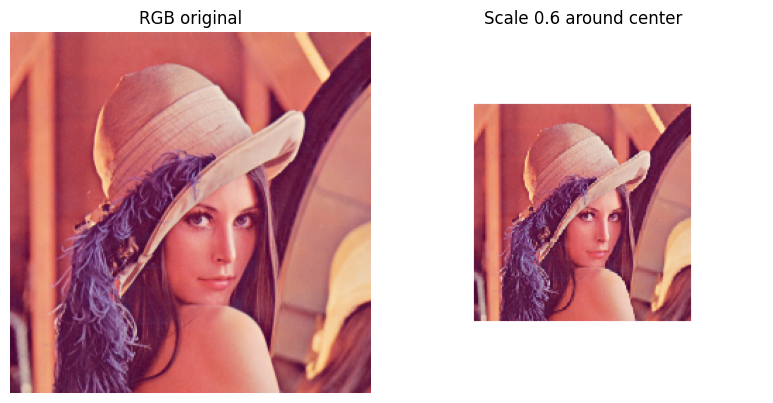

In [69]:
img = color_image
cen = centroid_image(img)

T = init_Transformation()
T = matrix_Translate(T, cen[1], cen[0])
T = matrix_Scale(T, 0.6, 0.6)
T = matrix_Translate(T, -cen[1], -cen[0])

out = img_transform(img, T)
show_images([img, out], ["RGB original", "Scale 0.6 around center"])

## 8) Rotation รอบจุดกึ่งกลาง

ใช้โครงสร้างเดียวกับ scaling แต่เปลี่ยนเป็น `matrix_Rotatef()` หลังจากเลื่อนจุดกึ่งกลางไปที่จุดกำเนิดแล้ว จึงหมุนภาพและเลื่อนกลับ

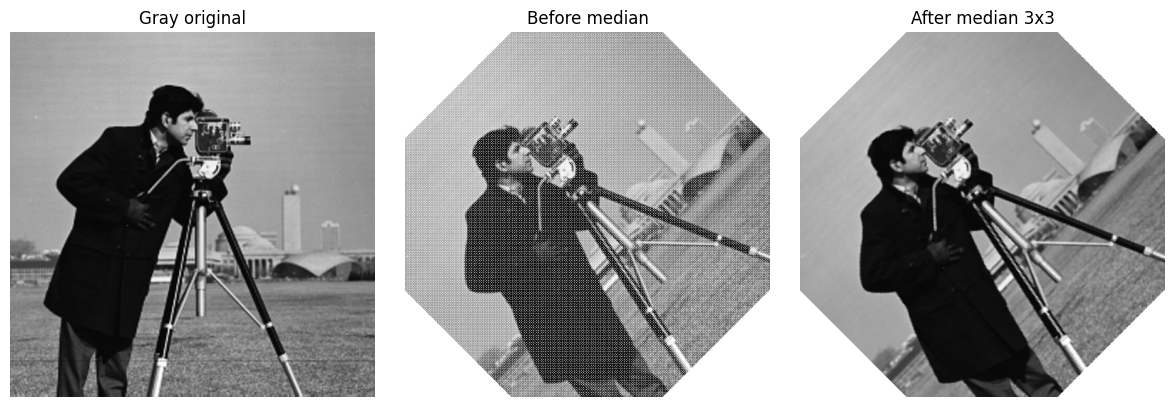

In [70]:
img = gray_image
cen = centroid_image(img)

T = init_Transformation()
T = matrix_Translate(T, cen[1], cen[0])
T = matrix_Rotatef(T, 45)
T = matrix_Translate(T, -cen[1], -cen[0])

out = img_transform(img, T)
out_new = cv2.medianBlur(out, 3)

show_images(
    [img, out, out_new],
    ["Gray original", "Before median", "After median 3x3"],
)

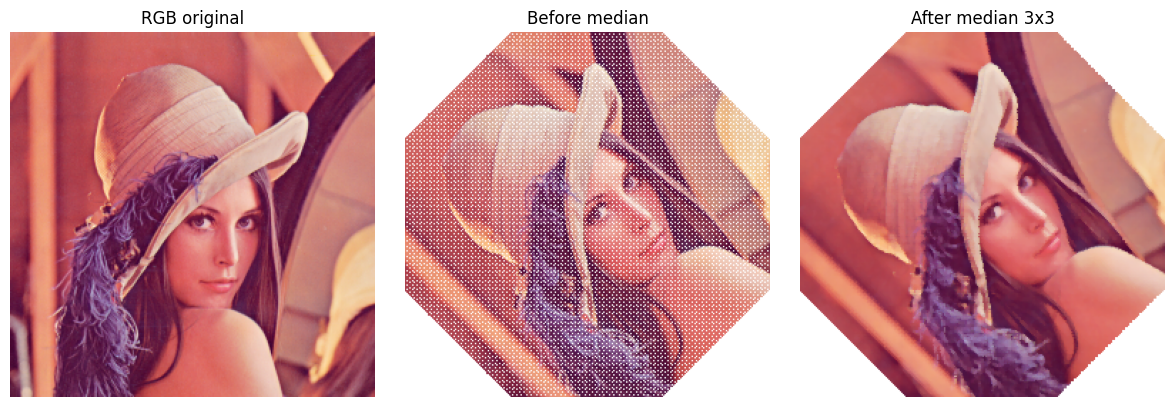

In [71]:
img = color_image
cen = centroid_image(img)

T = init_Transformation()
T = matrix_Translate(T, cen[1], cen[0])
T = matrix_Rotatef(T, 45)
T = matrix_Translate(T, -cen[1], -cen[0])

out = img_transform(img, T)
out_new = cv2.medianBlur(out, 3)

show_images(
    [img, out, out_new],
    ["RGB original", "Before median", "After median 3x3"],
)

## 9) Matrix Composition: Scaling และ Rotation

ตัวอย่างนี้รวม scaling และ rotation ไว้ใน `T` เดียว แล้วเรียก `img_transform()` เพียงครั้งเดียว

```python
T = init_Transformation()
T = matrix_Translate(T, cen[1], cen[0])
T = matrix_Scale(T, 0.5, 0.5)
T = matrix_Rotatef(T, 45)
T = matrix_Translate(T, -cen[1], -cen[0])
out = img_transform(img, T)
```

การเรียก `matrix_*` แต่ละครั้งจะคูณเมทริกซ์ใหม่ไว้ด้านหน้าของ `T` เดิม จึงได้เมทริกซ์สุดท้ายที่ใช้กับพิกัดทุกจุด

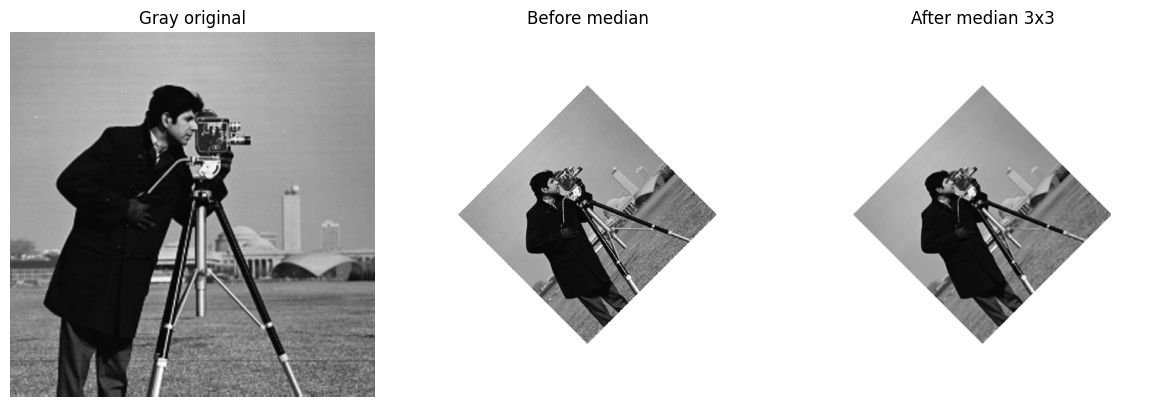

In [72]:
img = gray_image
cen = centroid_image(img)

T = init_Transformation()
T = matrix_Translate(T, cen[1], cen[0])
T = matrix_Scale(T, 0.5, 0.5)
T = matrix_Rotatef(T, 45)
T = matrix_Translate(T, -cen[1], -cen[0])

out = img_transform(img, T)
out_new = cv2.medianBlur(out, 3)

show_images(
    [img, out, out_new],
    ["Gray original", "Before median", "After median 3x3"],
)

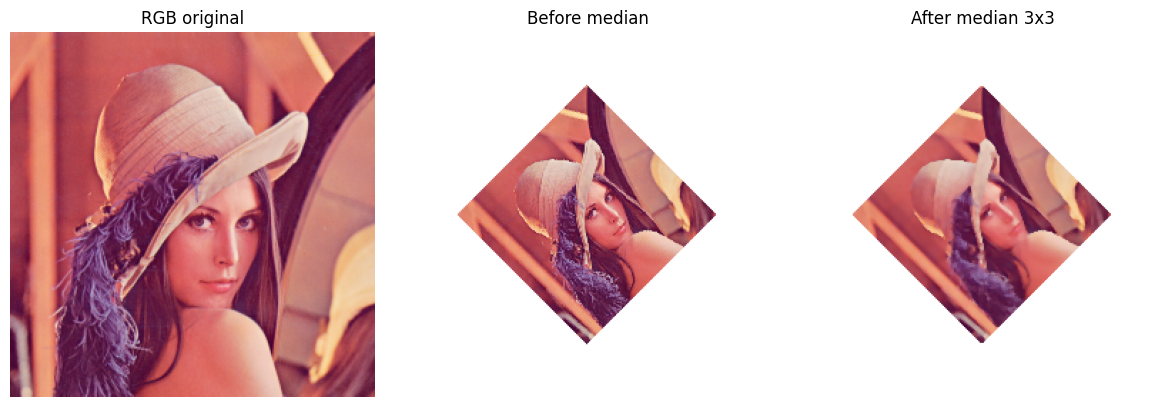

In [73]:
img = color_image
cen = centroid_image(img)

T = init_Transformation()
T = matrix_Translate(T, cen[1], cen[0])
T = matrix_Scale(T, 0.5, 0.5)
T = matrix_Rotatef(T, 45)
T = matrix_Translate(T, -cen[1], -cen[0])

out = img_transform(img, T)
out_new = cv2.medianBlur(out, 3)

show_images(
    [img, out, out_new],
    ["RGB original", "Before median", "After median 3x3"],
)

## 10) ช่องว่างจาก Forward Mapping

ฟังก์ชันในใบงานนี้นำพิกเซลต้นฉบับไปวางในตำแหน่งใหม่ วิธีนี้เรียกว่า **forward mapping** หลังแปลงตำแหน่งเป็นจำนวนเต็ม บางตำแหน่งอาจไม่มีพิกเซลมาตก จึงเห็นเป็นจุดดำหรือขอบไม่ต่อเนื่อง

`cv2.medianBlur(out, 3)` ช่วยลดช่องว่างและรอยหยักขนาดเล็กได้ชั่วคราว แต่ไม่ใช่ interpolation และอาจทำให้รายละเอียดภาพเปลี่ยน

## 11) ตรวจความถูกต้องเบื้องต้น

Identity matrix ต้องให้ภาพเดิม และการเลื่อนด้วย `(0, 0)` ต้องไม่เปลี่ยนตำแหน่งพิกเซล

In [74]:
small_gray = np.arange(20, dtype=np.uint8).reshape(4, 5)
small_color = np.dstack([small_gray, small_gray, small_gray])

identity = init_Transformation()

assert np.array_equal(img_transform(small_gray, identity), small_gray)
assert np.array_equal(img_transform(small_color, identity), small_color)
assert np.array_equal(img_translation(small_gray, 0, 0), small_gray)
assert np.array_equal(img_scaling(small_gray, 1, 1), small_gray)
assert np.array_equal(img_rotation(small_gray, 0), small_gray)

print("ตรวจแล้ว: transformation พื้นฐานทำงานถูกต้อง")

ตรวจแล้ว: transformation พื้นฐานทำงานถูกต้อง


## 12) แบบฝึกหัด

1. เปลี่ยน `tx` และ `ty` ให้ภาพเลื่อนไปทางซ้ายและขึ้นด้านบน
2. ทดลอง `sx=1.2, sy=0.7` แล้วอธิบายรูปร่างภาพที่เปลี่ยนไป
3. ทดลอง `theta=45` และ `theta=-45` แล้วเปรียบเทียบทิศทางการหมุน
4. เปลี่ยนลำดับ `matrix_Scale()` กับ `matrix_Rotatef()` แล้วสังเกตผล
5. เปลี่ยน median filter จาก `3` เป็น `5` แล้วสังเกตรายละเอียดภาพ

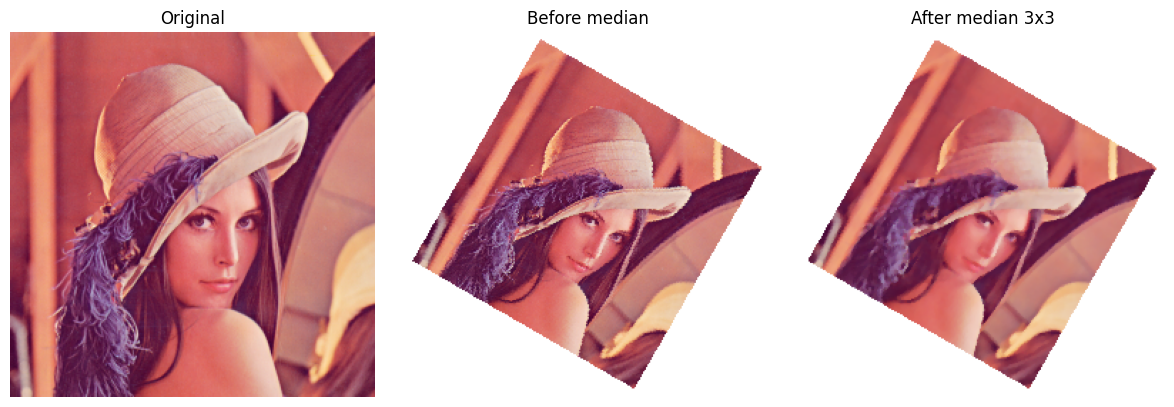

In [75]:
# ปรับค่าด้านล่างเพื่อทดลอง
img = color_image
cen = centroid_image(img)

scale_x, scale_y = 0.7, 0.7
angle = -30

T = init_Transformation()
T = matrix_Translate(T, cen[1], cen[0])
T = matrix_Scale(T, scale_x, scale_y)
T = matrix_Rotatef(T, angle)
T = matrix_Translate(T, -cen[1], -cen[0])

exercise_out = img_transform(img, T)
exercise_new = cv2.medianBlur(exercise_out, 3)

show_images(
    [img, exercise_out, exercise_new],
    ["Original", "Before median", "After median 3x3"],
)

## สรุป

- ทุก transformation ในใบงานนี้หาตำแหน่งใหม่ด้วย `np.matmul(xy, M)`
- Translation ใช้ `Ts`, scaling ใช้ `S` และ rotation ใช้ `R`
- `T` เริ่มจาก identity matrix ขนาด `3 x 3`
- `matrix_Translate()`, `matrix_Scale()` และ `matrix_Rotatef()` ใช้ประกอบหลาย transformation
- `img_transform(img, T)` ใช้ได้กับทั้งภาพระดับเทาและภาพสี
- Forward mapping อาจเกิดช่องว่าง จึงใช้ median filtering ลดปัญหาชั่วคราวก่อนเรียน interpolation